In [2]:
import kagglehub
import torch
import numpy as np
import pandas as pd
import os
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

device = "cuda" if torch.cuda.is_available() else "cpu"
path = kagglehub.dataset_download("andrewmvd/fetal-health-classification")
csv_path = os.path.join(path, "fetal_health.csv")

Using Colab cache for faster access to the 'fetal-health-classification' dataset.


In [3]:
df = pd.read_csv(csv_path)
df.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability  

In [5]:
df_X = df.drop(["fetal_health"], axis=1, inplace=False)
df_Y = df["fetal_health"]
classes = ["Healthy", "Suspect", "Pathological"]

In [6]:
df_X.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


In [7]:
df_Y.head()

,fetal_health
0,2.0
1,1.0
2,1.0
3,1.0
4,1.0


<Axes: ylabel='Count'>

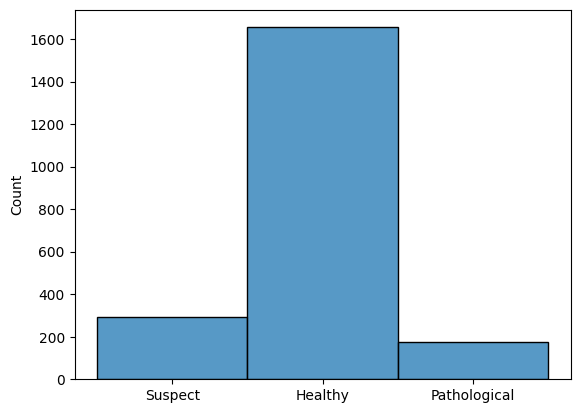

In [8]:
X = df_X.to_numpy(dtype=np.float32)

Y = df_Y.to_numpy(dtype=np.float32)
Y = Y - 1
sampler = RandomOverSampler(sampling_strategy="not majority") # Handle unbalanced classes by oversampling data
X_over, Y_over = sampler.fit_resample(X, Y)

X_train, X_test, Y_train, Y_test = train_test_split(X_over, Y_over, test_size=0.2, train_size=0.8) # Split dataset into train and test
X_train, X_val, Y_train, Y_val = train_test_split(X_train, Y_train, test_size=0.2, train_size=0.8) # Split train dataset into train and validation
vectorized = np.vectorize(lambda x: classes[int(x)])
Y_classes = vectorized(Y)
sns.histplot(Y_classes.astype(str))


In [9]:
# Convert preprocessed data to pytorch Dataset for training
train_dataloader = DataLoader(TensorDataset(torch.from_numpy(X_train).to(device), torch.from_numpy(Y_train).type(torch.LongTensor).to(device)), batch_size=64)
test_dataloader = DataLoader(TensorDataset(torch.from_numpy(X_test).to(device), torch.from_numpy(Y_test).type(torch.LongTensor).to(device)), batch_size=64)

In [16]:
class BaselineModel(torch.nn.Module):
   # One-layer fully connected model (Baseline)
  def __init__(self):
    super().__init__()
    self.linear = torch.nn.Linear(21, 3)
  def forward(self, x):
    return self.linear(x)

In [15]:
class FullyConnectedModel(torch.nn.Module):
   # Three-Layer fully connected model
  def __init__(self):
    super().__init__()
    self.fc1 = torch.nn.Linear(21, 128)
    self.fc2 = torch.nn.Linear(128, 128)
    self.fc3 = torch.nn.Linear(128, 3)
  def forward(self, x):
    x = self.fc1(x)
    x = self.fc2(x)
    x = self.fc3(x)
    return x

In [14]:
class FullyConnectedModelWithReLU(torch.nn.Module):
   # Three-Layer fully connected model with ReLU
  def __init__(self):
    super().__init__()
    self.fc1 = torch.nn.Linear(21, 128)
    self.relu1 = torch.nn.ReLU()
    self.fc2 = torch.nn.Linear(128, 128)
    self.relu2 = torch.nn.ReLU()
    self.fc3 = torch.nn.Linear(128, 3)
  def forward(self, x):
    x = self.fc1(x)
    x = self.relu1(x)
    x = self.fc2(x)
    x = self.relu2(x)
    x = self.fc3(x)
    return x

In [13]:
class FullyConnectedModelWithPReLU(torch.nn.Module):
  # Three-Layer fully connected model with PReLU
  def __init__(self):
    super().__init__()
    self.fc1 = torch.nn.Linear(21, 128)
    self.relu1 = torch.nn.PReLU()
    self.fc2 = torch.nn.Linear(128, 128)
    self.relu2 = torch.nn.PReLU()
    self.fc3 = torch.nn.Linear(128, 3)
  def forward(self, x):
    x = self.fc1(x)
    x = self.relu1(x)
    x = self.fc2(x)
    x = self.relu2(x)
    x = self.fc3(x)
    return x

In [10]:
class FourLayerFullyConnectedModelWithPReLU(torch.nn.Module):
  # Four-Layer fully connected model with PReLU
  def __init__(self):
    super().__init__()
    self.fc1 = torch.nn.Linear(21, 128)
    self.relu1 = torch.nn.PReLU()
    self.fc2 = torch.nn.Linear(128, 512)
    self.relu2 = torch.nn.PReLU()
    self.fc3 = torch.nn.Linear(512, 512)
    self.relu3 = torch.nn.PReLU()
    self.fc4 = torch.nn.Linear(512, 3)
  def forward(self, x):
    x = self.fc1(x)
    x = self.relu1(x)
    x = self.fc2(x)
    x = self.relu2(x)
    x = self.fc3(x)
    x = self.relu3(x)
    x = self.fc4(x)
    return x

In [12]:
class FiveLayerFullyConnectedModelWithPReLUAndDropout(torch.nn.Module):
  # Five-Layer fully connected model with PReLU and Dropout layers
  def __init__(self):
    super().__init__()
    self.stack = torch.nn.Sequential([
        torch.nn.Linear(21, 128),
        torch.nn.PReLU(),
        torch.nn.Dropout(0.5),
        torch.nn.Linear(128, 512),
        torch.nn.PReLU(),
        torch.nn.Dropout(0.5),
        torch.nn.Linear(512, 512),
        torch.nn.PReLU(),
        torch.nn.Dropout(0.5),
        torch.nn.Linear(512, 128),
        torch.nn.PReLU(),
        torch.nn.Dropout(0.5),
        torch.nn.Linear(128, 3)
    ])
  def forward(self, x):
    x = self.stack(x)
    return x

In [17]:
# Initialize models
baseline_model = BaselineModel().to(device)
fc_model = FullyConnectedModel().to(device)
fcr_model = FullyConnectedModelWithReLU().to(device)
fcp_model = FullyConnectedModelWithPReLU().to(device)
flfcp_model = FourLayerFullyConnectedModelWithPReLU().to(device)
flfcpd_model = FourLayerFullyConnectedModelWithPReLU().to(device)

In [18]:
# Initialize optimizers and schedulers. Also initialize CrossEntropyLoss.
baseline_optimizer = torch.optim.SGD(baseline_model.parameters(), lr=0.001)
crossentropy_loss_fn = torch.nn.CrossEntropyLoss()
baseline_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(baseline_optimizer, factor=0.1, patience=50)
fc_optimizer = torch.optim.SGD(fc_model.parameters(), lr=0.001)
fc_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(fc_optimizer, factor=0.1, patience=50)
fcr_optimizer = torch.optim.SGD(fcr_model.parameters(), lr=0.001)
fcr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(fcr_optimizer, factor=0.1, patience=50)
fcp_optimizer = torch.optim.SGD(fcp_model.parameters(), lr=0.001)
fcp_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(fcp_optimizer, factor=0.1, patience=50)
flfcp_optimizer = torch.optim.SGD(flfcp_model.parameters(), lr=0.001)
flfcp_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(flfcp_optimizer, factor=0.1, patience=50)
flfcpd_optimizer = torch.optim.SGD(flfcpd_model.parameters(), lr=0.001)
flfcpd_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(flfcpd_optimizer, factor=0.1, patience=50)


In [19]:
precisions = []
recalls = []

In [20]:
def validation(model, loss_fn):
  """
    Validation
  """
  total_loss = 0
  model.eval()
  with torch.no_grad():
    for batch, (x, y) in enumerate(test_dataloader):
      pred = model(x)
      total_loss += loss_fn(pred, y)
  return total_loss / len(test_dataloader)

In [21]:
def train(model, loss_fn, optimizer, scheduler):
  """
    Training Loop
  """
  model.train()
  for epoch in range(1000):
    for batch, (x, y) in enumerate(train_dataloader):
      pred = model(x)
      loss = loss_fn(pred, y)
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
    validation_loss = validation(model, loss_fn)
    print(validation_loss)
    scheduler.step(validation_loss)

In [22]:
def test(model, loss_fn):
  """
    Test Loop
  """
  preds, labels = [], []
  model.eval()
  correct= 0
  total_loss = 0
  with torch.no_grad():
    for batch, (x, y) in enumerate(test_dataloader):
      pred = model(x)
      total_loss += loss_fn(pred, y)
      pred2 = pred.argmax(1)
      preds.extend(pred2.cpu().tolist())
      labels.extend(y.cpu().tolist())
      correct += (pred.argmax(1) == y).type(torch.float).sum().item()
  confusion_array = confusion_matrix(labels, preds)
  precision = precision_score(labels, preds, average="macro") # Calculate precision
  recall = recall_score(labels, preds, average="macro") # Calculate recall
  precisions.append(precision)
  recalls.append(recall)
  return total_loss / len(test_dataloader), correct / len(test_dataloader.dataset), confusion_array # Return loss, accuracy, confusion array

tensor(47.4959, device='cuda:0')
tensor(41.8126, device='cuda:0')
tensor(8.6794, device='cuda:0')
tensor(14.5191, device='cuda:0')
tensor(26.9856, device='cuda:0')
tensor(14.9466, device='cuda:0')
tensor(3.2128, device='cuda:0')
tensor(17.2908, device='cuda:0')
tensor(16.5092, device='cuda:0')
tensor(18.0033, device='cuda:0')
tensor(16.5859, device='cuda:0')
tensor(15.7929, device='cuda:0')
tensor(17.1832, device='cuda:0')
tensor(16.5650, device='cuda:0')
tensor(16.9668, device='cuda:0')
tensor(16.6551, device='cuda:0')
tensor(16.7427, device='cuda:0')
tensor(17.2818, device='cuda:0')
tensor(18.0471, device='cuda:0')
tensor(18.9240, device='cuda:0')
tensor(16.2895, device='cuda:0')
tensor(18.6023, device='cuda:0')
tensor(16.4783, device='cuda:0')
tensor(18.2645, device='cuda:0')
tensor(16.9749, device='cuda:0')
tensor(12.4602, device='cuda:0')
tensor(3.8291, device='cuda:0')
tensor(17.4363, device='cuda:0')
tensor(3.1756, device='cuda:0')
tensor(3.1665, device='cuda:0')
tensor(11.9365,

<Axes: >

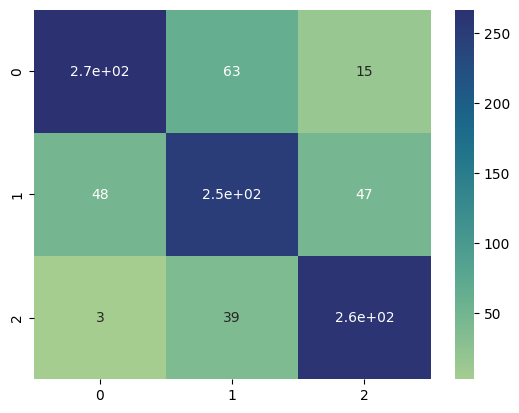

In [ ]:
train(baseline_model, crossentropy_loss_fn, baseline_optimizer, baseline_scheduler) # Train model
baseline_loss, baseline_accuracy, baseline_confusion = test(baseline_model, crossentropy_loss_fn) # Test model
sns.heatmap(baseline_confusion, annot=True, cmap="crest") # Generate confusion matrix

tensor(1.8840, device='cuda:0')
tensor(1.2064, device='cuda:0')
tensor(0.9041, device='cuda:0')
tensor(0.8067, device='cuda:0')
tensor(0.7570, device='cuda:0')
tensor(0.7262, device='cuda:0')
tensor(0.7051, device='cuda:0')
tensor(0.6898, device='cuda:0')
tensor(0.6780, device='cuda:0')
tensor(0.6687, device='cuda:0')
tensor(0.6611, device='cuda:0')
tensor(0.6547, device='cuda:0')
tensor(0.6492, device='cuda:0')
tensor(0.6445, device='cuda:0')
tensor(0.6403, device='cuda:0')
tensor(0.6365, device='cuda:0')
tensor(0.6332, device='cuda:0')
tensor(0.6301, device='cuda:0')
tensor(0.6273, device='cuda:0')
tensor(0.6247, device='cuda:0')
tensor(0.6223, device='cuda:0')
tensor(0.6201, device='cuda:0')
tensor(0.6181, device='cuda:0')
tensor(0.6161, device='cuda:0')
tensor(0.6143, device='cuda:0')
tensor(0.6126, device='cuda:0')
tensor(0.6110, device='cuda:0')
tensor(0.6095, device='cuda:0')
tensor(0.6080, device='cuda:0')
tensor(0.6067, device='cuda:0')
tensor(0.6054, device='cuda:0')
tensor(0

<Axes: >

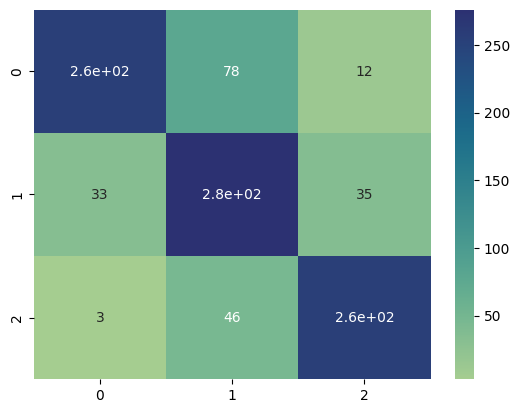

In [ ]:
train(fc_model, crossentropy_loss_fn, fc_optimizer, fc_scheduler) # Train model
fc_loss, fc_accuracy, fc_confusion = test(fc_model, crossentropy_loss_fn) # Test model
sns.heatmap(fc_confusion, annot=True, cmap="crest") # Generate confusion matrix

tensor(1.6149, device='cuda:0')
tensor(1.0673, device='cuda:0')
tensor(0.8638, device='cuda:0')
tensor(0.7667, device='cuda:0')
tensor(0.7198, device='cuda:0')
tensor(0.6889, device='cuda:0')
tensor(0.6704, device='cuda:0')
tensor(0.6593, device='cuda:0')
tensor(0.6509, device='cuda:0')
tensor(0.6439, device='cuda:0')
tensor(0.6386, device='cuda:0')
tensor(0.6341, device='cuda:0')
tensor(0.6310, device='cuda:0')
tensor(0.6275, device='cuda:0')
tensor(0.6266, device='cuda:0')
tensor(0.6250, device='cuda:0')
tensor(0.6206, device='cuda:0')
tensor(0.6161, device='cuda:0')
tensor(0.6107, device='cuda:0')
tensor(0.6064, device='cuda:0')
tensor(0.6077, device='cuda:0')
tensor(0.6078, device='cuda:0')
tensor(0.6085, device='cuda:0')
tensor(0.6061, device='cuda:0')
tensor(0.6020, device='cuda:0')
tensor(0.6014, device='cuda:0')
tensor(0.5991, device='cuda:0')
tensor(0.5964, device='cuda:0')
tensor(0.5959, device='cuda:0')
tensor(0.5955, device='cuda:0')
tensor(0.5931, device='cuda:0')
tensor(0

<Axes: >

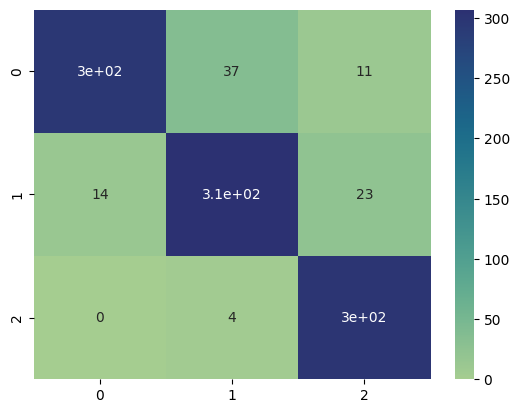

In [ ]:
train(fcr_model, crossentropy_loss_fn, fcr_optimizer, fcr_scheduler) # Train model
fcr_loss, fcr_accuracy, fcr_confusion = test(fcr_model, crossentropy_loss_fn) # Test model
sns.heatmap(fcr_confusion, annot=True, cmap="crest") # Generate confusion matrix

tensor(1.5389, device='cuda:0')
tensor(1.0213, device='cuda:0')
tensor(0.8476, device='cuda:0')
tensor(0.7768, device='cuda:0')
tensor(0.7293, device='cuda:0')
tensor(0.7001, device='cuda:0')
tensor(0.6780, device='cuda:0')
tensor(0.6635, device='cuda:0')
tensor(0.6500, device='cuda:0')
tensor(0.6355, device='cuda:0')
tensor(0.6253, device='cuda:0')
tensor(0.6181, device='cuda:0')
tensor(0.6082, device='cuda:0')
tensor(0.6027, device='cuda:0')
tensor(0.5967, device='cuda:0')
tensor(0.5900, device='cuda:0')
tensor(0.5871, device='cuda:0')
tensor(0.5868, device='cuda:0')
tensor(0.5869, device='cuda:0')
tensor(0.5824, device='cuda:0')
tensor(0.5778, device='cuda:0')
tensor(0.5803, device='cuda:0')
tensor(0.5732, device='cuda:0')
tensor(0.5698, device='cuda:0')
tensor(0.5700, device='cuda:0')
tensor(0.5742, device='cuda:0')
tensor(0.5710, device='cuda:0')
tensor(0.5725, device='cuda:0')
tensor(0.5689, device='cuda:0')
tensor(0.5700, device='cuda:0')
tensor(0.5654, device='cuda:0')
tensor(0

<Axes: >

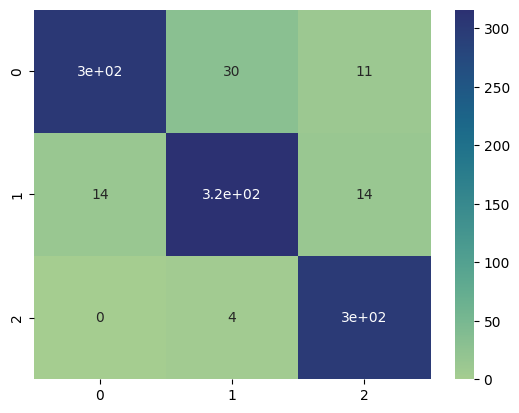

In [ ]:
train(fcp_model, crossentropy_loss_fn, fcp_optimizer, fcp_scheduler) # Train model
fcp_loss, fcp_accuracy, fcp_confusion = test(fcp_model, crossentropy_loss_fn) # Test model
sns.heatmap(fcp_confusion, annot=True, cmap="crest") # Generate confusion matrix

tensor(0.7339)
tensor(0.8684)
tensor(0.7757)
tensor(0.7287)
tensor(0.6983)
tensor(0.6760)
tensor(0.6599)
tensor(0.6460)
tensor(0.6343)
tensor(0.6244)
tensor(0.6149)
tensor(0.6062)
tensor(0.5994)
tensor(0.5927)
tensor(0.5860)
tensor(0.5784)
tensor(0.5743)
tensor(0.5681)
tensor(0.5629)
tensor(0.5587)
tensor(0.5545)
tensor(0.5492)
tensor(0.5449)
tensor(0.5411)
tensor(0.5372)
tensor(0.5335)
tensor(0.5293)
tensor(0.5263)
tensor(0.5236)
tensor(0.5204)
tensor(0.5173)
tensor(0.5147)
tensor(0.5118)
tensor(0.5093)
tensor(0.5066)
tensor(0.5037)
tensor(0.5007)
tensor(0.4976)
tensor(0.4957)
tensor(0.4929)
tensor(0.4908)
tensor(0.4885)
tensor(0.4859)
tensor(0.4839)
tensor(0.4808)
tensor(0.4783)
tensor(0.4759)
tensor(0.4736)
tensor(0.4714)
tensor(0.4687)
tensor(0.4664)
tensor(0.4644)
tensor(0.4623)
tensor(0.4606)
tensor(0.4588)
tensor(0.4571)
tensor(0.4554)
tensor(0.4534)
tensor(0.4517)
tensor(0.4503)
tensor(0.4484)
tensor(0.4470)
tensor(0.4450)
tensor(0.4437)
tensor(0.4416)
tensor(0.4404)
tensor(0.4

<Axes: >

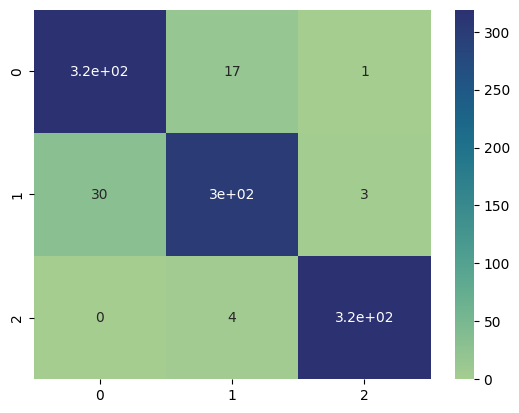

In [23]:
train(flfcp_model, crossentropy_loss_fn, flfcp_optimizer, flfcp_scheduler) # Train model
flfcp_loss, flfcp_accuracy, flfcp_confusion = test(flfcp_model, crossentropy_loss_fn) # Test model
sns.heatmap(flfcp_confusion, annot=True, cmap="crest") # Generate confusion matrix

tensor(1.3658, device='cuda:0')
tensor(1.0607, device='cuda:0')
tensor(0.8871, device='cuda:0')
tensor(0.7954, device='cuda:0')
tensor(0.7438, device='cuda:0')
tensor(0.7088, device='cuda:0')
tensor(0.6849, device='cuda:0')
tensor(0.6662, device='cuda:0')
tensor(0.6515, device='cuda:0')
tensor(0.6385, device='cuda:0')
tensor(0.6277, device='cuda:0')
tensor(0.6193, device='cuda:0')
tensor(0.6122, device='cuda:0')
tensor(0.6054, device='cuda:0')
tensor(0.5998, device='cuda:0')
tensor(0.5941, device='cuda:0')
tensor(0.5900, device='cuda:0')
tensor(0.5856, device='cuda:0')
tensor(0.5812, device='cuda:0')
tensor(0.5772, device='cuda:0')
tensor(0.5727, device='cuda:0')
tensor(0.5706, device='cuda:0')
tensor(0.5664, device='cuda:0')
tensor(0.5635, device='cuda:0')
tensor(0.5617, device='cuda:0')
tensor(0.5594, device='cuda:0')
tensor(0.5568, device='cuda:0')
tensor(0.5548, device='cuda:0')
tensor(0.5531, device='cuda:0')
tensor(0.5514, device='cuda:0')
tensor(0.5493, device='cuda:0')
tensor(0

<Axes: >

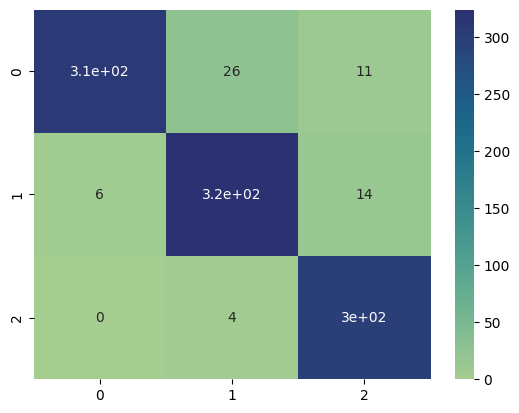

In [ ]:
train(flfcpd_model, crossentropy_loss_fn, flfcpd_optimizer, flfcpd_scheduler) # Train model
flfcpd_loss, flfcpd_accuracy, flfcpd_confusion = test(flfcpd_model, crossentropy_loss_fn) # Test model
sns.heatmap(flfcpd_confusion, annot=True, cmap="crest") # Generate confusion matrix

[Text(0.5, 1.0, 'Test Loss Comparison of model versions'),
 Text(0, 0.5, 'Model Version'),
 Text(0.5, 0, 'Test Loss')]

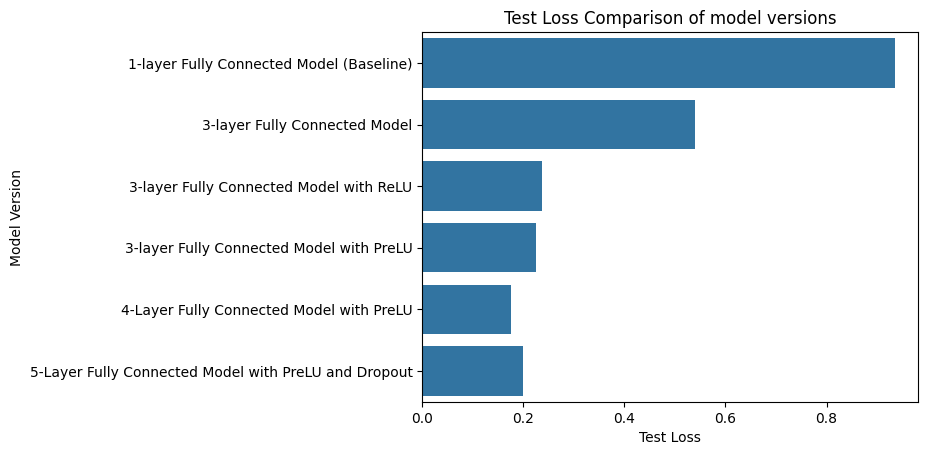

In [ ]:
accuracies = [baseline_accuracy, fc_accuracy, fcr_accuracy, fcp_accuracy, flfcp_accuracy, flfcpd_accuracy]
losses = np.array([baseline_loss.cpu(), fc_loss.cpu(), fcr_loss.cpu(), fcp_loss.cpu(), flfcp_loss.cpu(), flfcpd_loss.cpu()])
model_names = ["1-layer Fully Connected Model (Baseline)", "3-layer Fully Connected Model", "3-layer Fully Connected Model with ReLU", "3-layer Fully Connected Model with PreLU", "4-Layer Fully Connected Model with PreLU", "5-Layer Fully Connected Model with PreLU and Dropout"]
ax = sns.barplot(y=model_names, x=losses)
ax.set(title="Test Loss Comparison of model versions", ylabel="Model Version", xlabel="Test Loss")

[Text(0.5, 1.0, 'Recall Comparison of model versions'),
 Text(0, 0.5, 'Model Version'),
 Text(0.5, 0, 'Recall')]

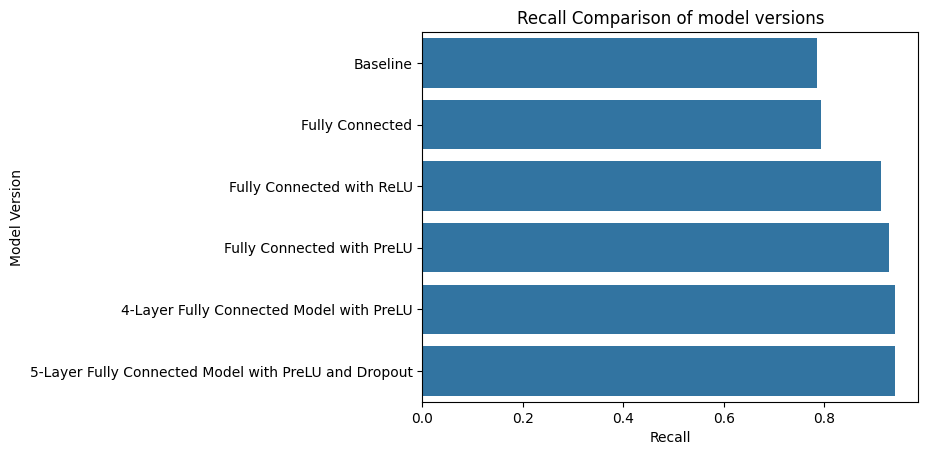

In [ ]:
ax_recall = sns.barplot(y=model_names, x=recalls)
ax_recall.set(title="Recall Comparison of model versions", ylabel="Model Version", xlabel="Recall")

[Text(0.5, 1.0, 'Precision Comparison of model versions'),
 Text(0, 0.5, 'Model Version'),
 Text(0.5, 0, 'Precision')]

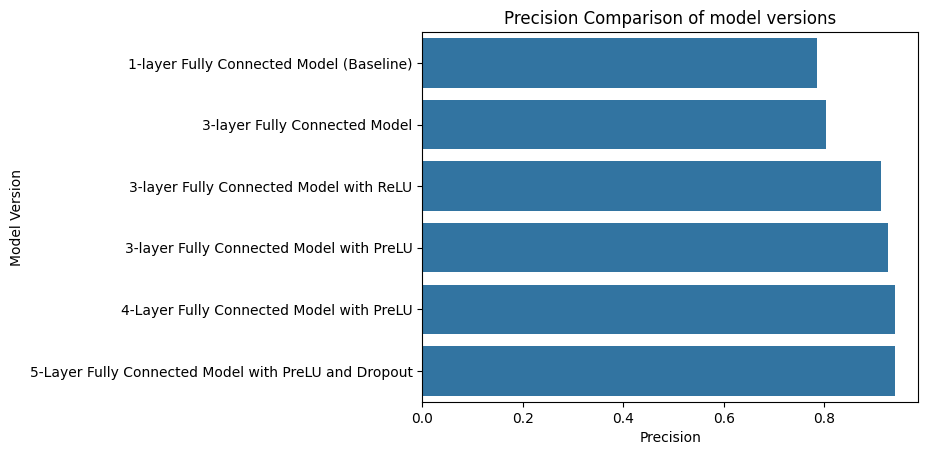

In [423]:
ax_precision = sns.barplot(y=model_names, x=precisions)
ax_precision.set(title="Precision Comparison of model versions", ylabel="Model Version", xlabel="Precision")

In [25]:
torch.save(flfcp_model.state_dict(), "model.pth") # Save model